<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [8]:
# Mengimpor dan menggabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
dataset = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

X = dataset[['review_count']].values
y = dataset['rating_cafe'].values  # Ubah menjadi satu kolom saja

In [9]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

In [10]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

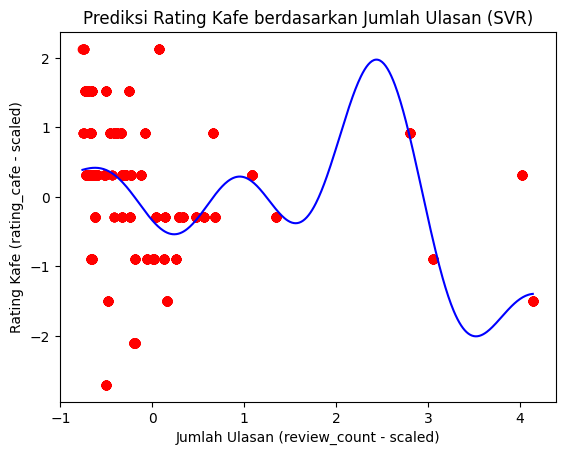

In [11]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Prediksi Rating Kafe berdasarkan Jumlah Ulasan (SVR)')
plt.xlabel('Jumlah Ulasan (review_count - scaled)')
plt.ylabel('Rating Kafe (rating_cafe - scaled)')
plt.show()

In [12]:
# Prediksi hasil
# Buat array 2D yang berisi jumlah ulasan yang akan diprediksi
jumlah_ulasan_prediksi = np.array([[1000]])
# Penskalaan fitur untuk data yang akan diprediksi
jumlah_ulasan_prediksi = sc_X.transform(jumlah_ulasan_prediksi)
# Melakukan prediksi menggunakan model SVR
rating_prediksi = regressor.predict(jumlah_ulasan_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
rating_prediksi = sc_y.inverse_transform(rating_prediksi.reshape(-1, 1))

In [13]:
# Menampilkan hasil prediksi
print("Prediksi Rating Kafe untuk Jumlah Ulasan 1000:", rating_prediksi[0])

Prediksi Rating Kafe untuk Jumlah Ulasan 1000: [4.57863334]


In [14]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.6383581474064274
MSE: 0.8680887851905795
RMSE: 0.9317128233477199
R-squared: 0.13191121480942025
